<a href="https://colab.research.google.com/github/Cynthia0209/Los-Angeles-Crime-Prediction/blob/main/G8_LA_Criminal_Report.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicting Weekly Crime Counts in Los Angeles

We wanted to see how much recent crime reports could tell us about the following week. Our goal was to predict the number of recorded incidents in each of LAPD's 21 patrol areas.

We include all crime types reported within 28 days of the incident. About 94% of the cases in our study period meet that rule. Using the same window for every week gives late reports the same amount of time to arrive.

We check the model on the 2023 holdout, then make a separate forecast for a week in 2024.

## Data source

We used LAPD's **Crime Data from 2020 to 2024**. The original file has 1,004,894 rows and 28 columns, with one row per recorded case. We saved our cleaned copy as `cleaned_export_final.zip`. [Data.gov listing](https://catalog.data.gov/dataset/crime-data-from-2020-to-present)

We can rerun the cleaning by saving the [original export](https://data.lacity.org/api/v3/views/2nrs-mtv8/export.csv?accessType=DOWNLOAD) as `export.csv`. In Colab, we can also upload it by setting `upload_in_colab = True`. We include the smaller weekly file so the forecasting section can run without the original download.

In [14]:
from pathlib import Path
import pandas as pd

raw_file = Path("export.csv")
upload_in_colab = False
df = None

if raw_file.is_file():
    df = pd.read_csv(raw_file, low_memory=False)
    display(df.head())
elif upload_in_colab:
    import io
    import os
    from google.colab import files

    print("Please upload your dataset file (CSV, Excel, etc.):")
    uploaded = files.upload()

    if uploaded:
        filename = list(uploaded.keys())[0]
        file_extension = os.path.splitext(filename)[1].lower()

        if file_extension == '.csv':
            df = pd.read_csv(io.BytesIO(uploaded[filename]))
            print(f"Successfully loaded {filename} as CSV!")
        elif file_extension in ['.xls', '.xlsx']:
            df = pd.read_excel(io.BytesIO(uploaded[filename]))
            print(f"Successfully loaded {filename} as Excel!")
        else:
            try:
                df = pd.read_csv(io.BytesIO(uploaded[filename]))
                print(f"Attempted loading {filename} as CSV by default.")
            except Exception as e:
                print(f"Could not load file. Unsupported format or error: {e}")
                df = None

        if df is not None:
            print("\nFirst 5 rows of the dataset:")
            display(df.head())
    else:
        print("No file was uploaded.")
else:
    print("To rerun cleaning, download the source CSV above as export.csv.")

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,211507896,2021 Apr 11 12:00:00 AM,2020 Nov 07 12:00:00 AM,845,15,N Hollywood,1502,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,7800 BEEMAN AV,NaN,34.2124,-118.4092
1,201516622,2020 Oct 21 12:00:00 AM,2020 Oct 18 12:00:00 AM,1845,15,N Hollywood,1521,1,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",...,IC,Invest Cont,230.0,NaN,NaN,NaN,ATOLL AV,N GAULT,34.1993,-118.4203
2,240913563,2024 Dec 10 12:00:00 AM,2020 Oct 30 12:00:00 AM,1240,9,Van Nuys,933,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,14600 SYLVAN ST,NaN,34.1847,-118.4509
3,210704711,2020 Dec 24 12:00:00 AM,2020 Dec 24 12:00:00 AM,1310,7,Wilshire,782,1,331,THEFT FROM MOTOR VEHICLE - GRAND ($950.01 AND ...,...,IC,Invest Cont,331.0,NaN,NaN,NaN,6000 COMEY AV,NaN,34.0339,-118.3747
4,201418201,2020 Oct 03 12:00:00 AM,2020 Sep 29 12:00:00 AM,1830,14,Pacific,1454,1,420,THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),...,IC,Invest Cont,420.0,NaN,NaN,NaN,4700 LA VILLA MARINA,NaN,33.9813,-118.4350


We first checked the original file with `.info()`. The missing-value counts showed which fields needed attention, and `.duplicated()` showed whether we had any repeated rows.

We rerun these checks when we load the original CSV. Without it, we show the summary we saved when we checked the original file.

In [15]:
if df is not None:
    print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")

    print("--- Dataset Information ---")
    df.info()

    print("\n--- Missing Values Statistics ---")
    missing_count = df.isnull().sum()
    missing_percent = (df.isnull().sum() / len(df)) * 100
    missing_df = pd.DataFrame({'Missing Count': missing_count, 'Percentage (%)': missing_percent})
    display(missing_df.sort_values(by='Missing Count', ascending=False))

    print("\n--- Duplicate Rows Count ---")
    duplicate_count = df.duplicated().sum()
    print(f"Total duplicated rows: {duplicate_count}")
else:
    print("Saved checks from our original LAPD export (export.csv was not loaded).")
    print("Rows: 1,004,894 | Columns: 28 | Duplicate rows: 0")
    print("Most missing: Crm Cd 4 (99.99%), Crm Cd 3 (99.77%),")
    print("Crm Cd 2 (93.12%), and Cross Street (84.65%).")

Dataset Dimensions: 1004894 rows, 28 columns

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004894 entries, 0 to 1004893
Data columns (total 28 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   DR_NO           1004894 non-null  int64  
 1   Date Rptd       1004894 non-null  object 
 2   DATE OCC        1004894 non-null  object 
 3   TIME OCC        1004894 non-null  int64  
 4   AREA            1004894 non-null  int64  
 5   AREA NAME       1004894 non-null  object 
 6   Rpt Dist No     1004894 non-null  int64  
 7   Part 1-2        1004894 non-null  int64  
 8   Crm Cd          1004894 non-null  int64  
 9   Crm Cd Desc     1004894 non-null  object 
 10  Mocodes         853296 non-null   object 
 11  Vict Age        1004894 non-null  int64  
 12  Vict Sex        860263 non-null   object 
 13  Vict Descent    860251 non-null   object 
 14  Premis Cd       1004878 non-null  float64
 15  Premis De

,Missing Count,Percentage (%)
Crm Cd 4,1004830,99.993631
Crm Cd 3,1002580,99.769727
Crm Cd 2,935740,93.118279
Cross Street,850666,84.652312
Weapon Used Cd,677678,67.437760
Weapon Desc,677678,67.437760
Mocodes,151598,15.085969
Vict Descent,144643,14.393856
Vict Sex,144631,14.392662
Premis Desc,588,0.058514



--- Duplicate Rows Count ---
Total duplicated rows: 0


## Data cleaning

We dropped `Crm Cd 2`, `Crm Cd 3`, `Crm Cd 4`, and `Cross Street` because they were mostly empty. We kept cases with missing weapon information by filling the code with `-1` and the description with `Unknown`. After dropping rows with missing values in the remaining fields, we had 852,484 rows.

We then kept ages from 1 to 100 and coordinates within a rectangle around Los Angeles. This left 727,977 rows. We put both dates in YYYY-MM-DD format and checked that the result matched our saved CSV.

In [16]:
if df is not None:
    cleaned = df.drop(columns=["Crm Cd 2", "Crm Cd 3", "Crm Cd 4", "Cross Street"])
    cleaned = cleaned.fillna({"Weapon Used Cd": -1, "Weapon Desc": "Unknown"})
    cleaned = cleaned.dropna()
    print(f"After handling missing values: {len(cleaned):,} rows")

    cleaned = cleaned[cleaned["Vict Age"].between(1, 100)]
    print(f"After filtering ages: {len(cleaned):,} rows")

    in_la = cleaned["LAT"].between(33.7, 34.35) & cleaned["LON"].between(-118.7, -118.15)
    cleaned = cleaned[in_la].copy()

    for column in ["Date Rptd", "DATE OCC"]:
        cleaned[column] = pd.to_datetime(cleaned[column], format="mixed").dt.strftime("%Y-%m-%d")

    print(f"After filtering coordinates: {len(cleaned):,} rows and {cleaned.shape[1]} columns")
    team_export = pd.read_csv("cleaned_export_final.zip", low_memory=False)
    print("Matches our saved CSV:", cleaned.reset_index(drop=True).equals(team_export))
else:
    print("We use our saved cleaned ZIP below. Load export.csv to rerun these steps.")

After handling missing values: 852,484 rows
After filtering ages: 729,638 rows
After filtering coordinates: 727,977 rows and 24 columns
Matches our saved CSV: True


We can set `save_rebuilt_zip = True` to export another copy of our cleaned CSV.

In [17]:
save_rebuilt_zip = False

if df is not None and save_rebuilt_zip:
    cleaned.to_csv(
        "cleaned_export_rebuilt.zip",
        index=False,
        compression={"method": "zip", "archive_name": "cleaned_export_final.csv"},
    )

## What we learned from the case records

We started with one row per case. The columns we use most in the forecast are the two dates and the patrol area. We list the other fields here to show what was available in the original records.

| Column | What it means |
|---|---|
| `DR_NO` | LAPD case number. We use it to identify a case. |
| `DATE OCC` | Date the incident happened. We use it to assign each case to its occurrence week. |
| `Date Rptd` | Date the incident was reported to LAPD. We use it to tell when the report became available. |
| `TIME OCC` | Time of the incident in 24-hour HHMM format. For example, `845` is 8:45 a.m. |
| `AREA` | Number identifying one of LAPD's 21 patrol areas. |
| `AREA NAME` | Name of the patrol area, such as Hollywood. |
| `Rpt Dist No` | Reporting district number. A reporting district is a smaller area within a patrol area. |
| `LOCATION` | Approximate address, given at the hundred-block level. |
| `LAT` / `LON` | Latitude and longitude recorded for the incident. |
| `Part 1-2` | LAPD's broad Part 1 or Part 2 crime classification. |
| `Crm Cd` / `Crm Cd Desc` | Crime type code and its description. For example, `210` is robbery. |
| `Crm Cd 1` | First crime code listed on the case record. |
| `Mocodes` | Codes describing how the incident was carried out, such as actions recorded by police. |
| `Vict Age` | Recorded age of the victim, in years. |
| `Vict Sex` | Recorded victim sex. LAPD documents `F` as female, `M` as male and `X` as unknown. |
| `Vict Descent` | LAPD's recorded victim descent category. |
| `Premis Cd` / `Premis Desc` | Code and description for the type of place, such as a street or a parking lot. |
| `Weapon Used Cd` / `Weapon Desc` | Weapon code and description. We use `-1` and `Unknown` for missing entries. |
| `Status` / `Status Desc` | Status code and description for the case, such as Investigation Continued. |

In our original file, we also had three fields for additional crime codes (`Crm Cd 2` through `Crm Cd 4`) and `Cross Street`, which gives the nearby intersecting street. We dropped these during cleaning. [LAPD column definitions](https://data.lacity.org/Public-Safety/Crime-Data-from-2020-to-2024/2nrs-mtv8)

### Summary of the cleaned file

We use `.info()` to see the types and number of non-null values. With `.describe()`, we read `50%` as the median and `min` and `max` as the range. For text fields, `top` is the most common value and `freq` is how often it appears.

In [18]:
clean_data = pd.read_csv(
    "cleaned_export_final.zip",
    parse_dates=["DATE OCC", "Date Rptd"],
    low_memory=False,
)
clean_data.info(show_counts=True)

display(clean_data[["Vict Age", "LAT", "LON"]].describe().round(4))
display(clean_data[["AREA NAME", "Crm Cd Desc", "Vict Sex", "Weapon Desc"]].describe())
display(clean_data[["DATE OCC", "Date Rptd"]].agg(["min", "max"]))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 727977 entries, 0 to 727976
Data columns (total 24 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   DR_NO           727977 non-null  int64         
 1   Date Rptd       727977 non-null  datetime64[ns]
 2   DATE OCC        727977 non-null  datetime64[ns]
 3   TIME OCC        727977 non-null  int64         
 4   AREA            727977 non-null  int64         
 5   AREA NAME       727977 non-null  object        
 6   Rpt Dist No     727977 non-null  int64         
 7   Part 1-2        727977 non-null  int64         
 8   Crm Cd          727977 non-null  int64         
 9   Crm Cd Desc     727977 non-null  object        
 10  Mocodes         727977 non-null  object        
 11  Vict Age        727977 non-null  int64         
 12  Vict Sex        727977 non-null  object        
 13  Vict Descent    727977 non-null  object        
 14  Premis Cd       727977 non-null  flo

,Vict Age,LAT,LON
count,727977.0000,727977.0000,727977.0000
mean,39.5024,34.0756,-118.3571
std,15.5714,0.1099,0.1052
min,2.0000,33.7059,-118.6676
25%,28.0000,34.0163,-118.4335
50%,37.0000,34.0594,-118.3265
75%,50.0000,34.1660,-118.2761
max,99.0000,34.3343,-118.1554


,AREA NAME,Crm Cd Desc,Vict Sex,Weapon Desc
count,727977,727977,727977,727977
unique,21,138,4,80
top,Central,BATTERY - SIMPLE ASSAULT,M,Unknown
freq,51837,73420,366843,428495


,DATE OCC,Date Rptd
min,2020-01-01,2020-01-01
max,2024-12-30,2025-03-28


We found no missing values across the 24 columns in our cleaned copy. There are still 428,495 weapon descriptions marked `Unknown` because we filled missing values with that label. The median recorded age is 37, and the ages range from 2 to 99. We also saw that some incidents from 2024 were reported in 2025. That was a useful reminder to keep the two dates separate.

## From cases to weekly counts

We went back to the original file for the forecast so we could count cases even when details like age or weapon were missing. We grouped the records by patrol area and week. The weekly table has two counts:

- `cases` is the number of incidents that **happened** that week and were reported within 28 days. This is our target.
- `reports` is the number of reports LAPD **received** that week. Earlier weeks' reports give us information to make the next prediction.

We can rebuild the table from the original file and save it with `save_weekly_counts = True`. Otherwise, our code reads `weekly_crime_counts.csv`.

In [19]:
import matplotlib.pyplot as plt
import numpy as np

weeks = pd.date_range("2020-01-06", "2023-12-25", freq="W-MON")
save_weekly_counts = False

if df is not None:
    columns = ["DR_NO", "AREA", "AREA NAME", "DATE OCC", "Date Rptd"]
    records = df[columns].dropna().drop_duplicates("DR_NO").copy()
    records["DATE OCC"] = pd.to_datetime(records["DATE OCC"], format="mixed")
    records["Date Rptd"] = pd.to_datetime(records["Date Rptd"], format="mixed")

    # We use the Monday of each week for both dates.
    records["occ_week"] = records["DATE OCC"].dt.to_period("W-SUN").dt.start_time
    records["report_week"] = records["Date Rptd"].dt.to_period("W-SUN").dt.start_time
    delay = (records["Date Rptd"] - records["DATE OCC"]).dt.days
    timely = records[delay.between(0, 28)]

    areas = records[["AREA", "AREA NAME"]].drop_duplicates()
    calendar = pd.DataFrame({"week": weeks})
    weekly = calendar.merge(areas, how="cross")

    counts = timely.groupby(["occ_week", "AREA"]).size().reset_index(name="cases")
    counts = counts.rename(columns={"occ_week": "week"})
    reports = records.groupby(["report_week", "AREA"]).size().reset_index(name="reports")
    reports = reports.rename(columns={"report_week": "week"})
    weekly = weekly.merge(counts, on=["AREA", "week"], how="left")
    weekly = weekly.merge(reports, on=["AREA", "week"], how="left")
    weekly[["cases", "reports"]] = weekly[["cases", "reports"]].fillna(0).astype(int)
    weekly = weekly.sort_values(["week", "AREA"]).reset_index(drop=True)

    if save_weekly_counts:
        weekly.to_csv("weekly_crime_counts.csv", index=False)
else:
    weekly = pd.read_csv("weekly_crime_counts.csv", parse_dates=["week"])

weekly.head()

,week,AREA,AREA NAME,cases,reports
0,2020-01-06,1,Central,260,242
1,2020-01-06,2,Rampart,164,146
2,2020-01-06,3,Southwest,210,203
3,2020-01-06,4,Hollenbeck,143,136
4,2020-01-06,5,Harbor,157,152


## Exploring the weekly counts

Before we fit the models, we made two plots using 2020 and 2021. We wanted to see how much the total changed from week to week and how different the patrol areas were from each other.

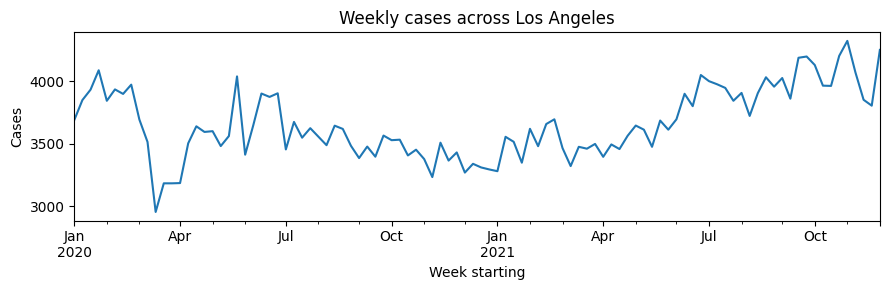

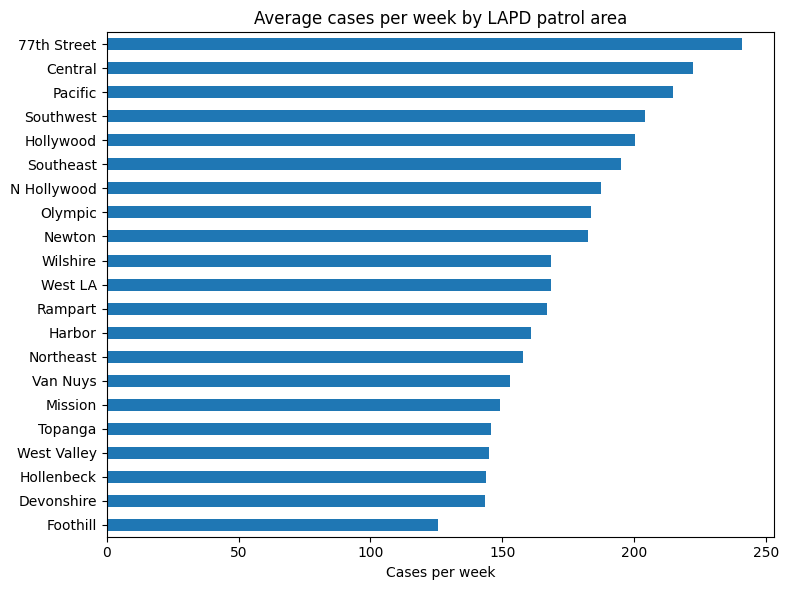

In [20]:
validation_start = pd.Timestamp("2022-01-03")
test_start = pd.Timestamp("2023-01-02")
last_train_week = validation_start - pd.DateOffset(weeks=5)
last_val_week = test_start - pd.DateOffset(weeks=5)
eda = weekly[weekly["week"] <= last_train_week]

city_counts = eda.groupby("week")["cases"].sum()
city_counts.plot(figsize=(9, 3), title="Weekly cases across Los Angeles")
plt.xlabel("Week starting")
plt.ylabel("Cases")
plt.tight_layout()
plt.show()

area_average = eda.groupby("AREA NAME")["cases"].mean().sort_values()
area_average.plot.barh(figsize=(8, 6), title="Average cases per week by LAPD patrol area")
plt.xlabel("Cases per week")
plt.ylabel("")
plt.tight_layout()
plt.show()

We saw the total move between about 3,000 and 4,300 cases per week. We also found that 77th Street averaged about 241 cases per week, while Foothill averaged about 126. These differences gave us a reason to include both the patrol area and the recent report counts in the model.

## Setting up the forecast

For each week, we used four inputs: the patrol area, the month, last week's report count, and the average report count over the previous four weeks. We used `.shift(1)` so the report counts always came from before the week we were predicting.

We fitted the models on 2020–21 and picked one using 2022. We kept 2023 for a separate validation check. We left four weeks between these periods to allow for late reports. We stopped before LAPD changed reporting systems in 2024. [LAPD reporting notes](https://data.lacity.org/Public-Safety/Crime-Data-from-2020-to-2024/2nrs-mtv8)

In [21]:
weekly = weekly.sort_values(["AREA", "week"]).reset_index(drop=True)
weekly["last_week_reports"] = weekly.groupby("AREA")["reports"].shift(1)

weekly["last_4_week_avg"] = weekly.groupby("AREA")["last_week_reports"].transform(
    lambda past: past.rolling(4).mean()
)
weekly["month"] = weekly["week"].dt.month
weekly = weekly.dropna(subset=["last_4_week_avg"])
weekly = weekly.sort_values(["week", "AREA"]).reset_index(drop=True)

train = weekly["week"] <= last_train_week
val = weekly["week"].between(validation_start, last_val_week)
test = weekly["week"] >= test_start

predictors = ["last_week_reports", "last_4_week_avg", "month", "AREA"]
X = pd.get_dummies(weekly[predictors], columns=["month", "AREA"], dtype=int)
y = weekly["cases"]

X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]

for name, labels in [("Train", y_train), ("Validation", y_val), ("2023 held-out validation", y_test)]:
    print(f"{name}: {len(labels):,} area weeks")

weekly.loc[train, ["last_week_reports", "last_4_week_avg", "cases"]].corr().round(2)

Train: 2,016 area weeks
Validation: 1,008 area weeks
2023 held-out validation: 1,092 area weeks


,last_week_reports,last_4_week_avg,cases
last_week_reports,1.00,0.91,0.77
last_4_week_avg,0.91,1.00,0.82
cases,0.77,0.82,1.00


In our training data, the four-week average had a correlation of 0.82 with the target, compared with 0.77 for last week's count. We kept both because they tell us about recent activity over different periods.

## Comparing the models

We compared Linear Regression, Random Forest, and XGBoost. For a simple comparison, we also tried using the previous four weeks' average as the forecast. We tuned the two tree models with `GridSearchCV`, using earlier weeks to fit and later weeks to check each setting.

We compared the models with **mean absolute error (MAE)**. An MAE of 15 means we miss the actual count by 15 cases per area per week on average. The next cell installs XGBoost and Folium if our notebook kernel is missing them.

In [22]:
from importlib.util import find_spec

if find_spec("xgboost") is None:
    %pip install -q xgboost

if find_spec("folium") is None:
    %pip install -q folium


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/Cellar/jupyterlab/4.4.9/libexec/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/Cellar/jupyterlab/4.4.9/libexec/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=42, n_jobs=2),
}
parameters = {
    "Random Forest": {"max_depth": [4, 8], "min_samples_leaf": [3, 8]},
    "XGBoost": {"max_depth": [2, 4], "learning_rate": [0.03, 0.10]},
}

rows_per_week = weekly["AREA"].nunique()
weeks_per_fold = weekly.loc[train, "week"].nunique() // 4
cv = TimeSeriesSplit(n_splits=3, test_size=weeks_per_fold * rows_per_week,
                     gap=4 * rows_per_week)

In [11]:
simple_train = mean_absolute_error(y_train, X_train["last_4_week_avg"])
simple_val = mean_absolute_error(y_val, X_val["last_4_week_avg"])
results = [["Previous 4-week average", simple_train, simple_val]]
fitted = {}

for name, model in models.items():
    if name in parameters:
        search = GridSearchCV(model, parameters[name], cv=cv, scoring="neg_mean_absolute_error")
        search.fit(X_train, y_train)
        model = search.best_estimator_
        print(name, search.best_params_)
    else:
        model.fit(X_train, y_train)
    fitted[name] = model
    train_mae = mean_absolute_error(y_train, model.predict(X_train).clip(0))
    val_mae = mean_absolute_error(y_val, model.predict(X_val).clip(0))
    results.append([name, train_mae, val_mae])

scores = pd.DataFrame(results, columns=["Model", "Train MAE", "Validation MAE"])
scores = scores.set_index("Model").sort_values("Validation MAE")
scores.round(2)

Random Forest {'max_depth': 4, 'min_samples_leaf': 3}


XGBoost {'learning_rate': 0.1, 'max_depth': 2}


,Train MAE,Validation MAE
Model,,
Linear Regression,14.67,21.46
XGBoost,14.35,22.15
Random Forest,14.94,22.17
Previous 4-week average,17.83,24.29


Linear Regression gave us the lowest validation MAE at **21.46**. XGBoost and Random Forest were both around **22**. Since the linear model did best on 2022, we used it for a separate validation check on 2023.

In [12]:
best_name = scores.loc[list(fitted), "Validation MAE"].idxmin()
best_model = fitted[best_name]

validation_results = weekly.loc[test, ["week", "AREA", "AREA NAME", "cases"]].copy()
validation_results["prediction"] = best_model.predict(X_test).clip(0)

print("Selected model:", best_name)
print("2023 held-out MAE:", round(mean_absolute_error(y_test, validation_results["prediction"]), 2))
print("2023 held-out RMSE:", round(mean_squared_error(y_test, validation_results["prediction"]) ** 0.5, 2))
print("2023 four-week-average MAE:", round(mean_absolute_error(y_test, X_test["last_4_week_avg"]), 2))

Selected model: Linear Regression
2023 held-out MAE: 18.22
2023 held-out RMSE: 24.67
2023 four-week-average MAE: 21.88


On the 2023 holdout, our model missed by about 18 cases per area per week, compared with about 22 for the four-week average. We also checked the coefficients for our two recent-report inputs. We read these as changes in the fitted count when the other inputs are held fixed.

In [13]:
if best_name == "Linear Regression":
    coefficients = pd.Series(best_model.coef_, index=X_train.columns)
    display(coefficients[["last_week_reports", "last_4_week_avg"]].round(2))
else:
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
    display(importance.sort_values(ascending=False).head())

last_week_reports    0.11
last_4_week_avg      0.49
dtype: float64

## Forecasting the first week of 2024

We use 2023 to check accuracy, then forecast **January 1–7, 2024**, the first week after the holdout. At the start of that week, we can use reports LAPD received from **December 4–31, 2023**. We use the last week's count and the average across those four weeks, along with the month and patrol area. The model and its settings were already chosen before we checked 2023.

In [14]:
forecast_week = pd.Timestamp("2024-01-01")
if forecast_week.dayofweek != 0 or forecast_week <= weekly["week"].max():
    raise ValueError("Choose a Monday after the 2023 holdout.")

prior_weeks = pd.date_range(end=forecast_week, periods=5, freq="W-MON")[:-1]
recent = weekly.loc[weekly["week"].isin(prior_weeks), ["week", "AREA", "reports"]]

area_names = weekly[["AREA", "AREA NAME"]].drop_duplicates()
report_table = recent.pivot(index="AREA", columns="week", values="reports")
report_table = report_table.reindex(index=area_names["AREA"], columns=prior_weeks)
if report_table.isna().any().any():
    raise ValueError("Supply report counts for all 21 patrol areas in each of the four previous weeks.")

new_data = pd.DataFrame({
    "last_week_reports": report_table[prior_weeks[-1]],
    "last_4_week_avg": report_table.mean(axis=1),
}).reset_index()
new_data["month"] = forecast_week.month

X_new = pd.get_dummies(new_data[predictors], columns=["month", "AREA"], dtype=int)
X_new = X_new.reindex(columns=X_train.columns, fill_value=0)
new_data["prediction"] = best_model.predict(X_new).clip(0)
new_forecast = new_data.merge(area_names, on="AREA")

print("Forecast week starts:", forecast_week.date())
new_forecast[["AREA NAME", "last_week_reports", "last_4_week_avg", "prediction"]].head().round(1)

Forecast week starts: 2024-01-01


,AREA NAME,last_week_reports,last_4_week_avg,prediction
0,Central,350,364.2,298.2
1,Rampart,188,218.0,188.3
2,Southwest,210,233.8,211.3
3,Hollenbeck,145,162.0,147.3
4,Harbor,181,185.2,169.1


## Mapping the new forecast

We use the same Folium choropleth method from class. We match `AREA` in our forecasts to `PREC` in the patrol boundaries. We color each area by its predicted count, and we can click an area to see that count. [LAPD patrol boundaries](https://services5.arcgis.com/7nsPwEMP38bSkCjy/arcgis/rest/services/LAPD_Division/FeatureServer/0)

In [15]:
import json
import folium

with open("lapd_areas.geojson") as file:
    boundaries = json.load(file)

# We use the patrol area number to match the forecast to each boundary.
area_lookup = new_forecast.set_index("AREA")
for area in boundaries["features"]:
    properties = area["properties"]
    row = area_lookup.loc[properties["PREC"]]
    properties["area_name"] = row["AREA NAME"]
    properties["predicted"] = round(float(row["prediction"]), 1)

m = folium.Map(
    location=[34.05, -118.38],
    zoom_start=10,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri",
)
colors = folium.Choropleth(
    geo_data=boundaries,
    data=new_forecast,
    columns=["AREA", "prediction"],
    key_on="feature.properties.PREC",
    fill_color="YlOrRd",
    fill_opacity=0.75,
    line_opacity=0.8,
    legend_name=f"Predicted cases | Week of {forecast_week:%Y-%m-%d}",
    highlight=True,
).add_to(m)

popup = folium.GeoJsonPopup(
    fields=["area_name", "predicted"],
    aliases=["Patrol area:", "Predicted cases:"],
)
popup.add_to(colors.geojson)
m.fit_bounds(colors.geojson.get_bounds())
m.save("weekly_crime_forecast.html")
m

In [16]:
display(new_forecast[["AREA", "AREA NAME", "prediction"]].sort_values("prediction", ascending=False).round(1))

,AREA,AREA NAME,prediction
0,1,Central,298.2
11,12,77th Street,241.6
13,14,Pacific,221.5
2,3,Southwest,211.3
5,6,Hollywood,204.4
14,15,N Hollywood,202.8
19,20,Olympic,200.0
6,7,Wilshire,197.0
12,13,Newton,190.1
1,2,Rampart,188.3


## Conclusion

We got an MAE of **18.22** cases per patrol area per week on the 2023 holdout, compared with **21.88** for the four-week average. That gave us a reason to use the linear model for our next forecast.

We then used the last four weeks of December reports to forecast January 1–7, 2024, for all 21 patrol areas. The map shows the predicted counts for that new week. We kept the accuracy check separate, using the observed counts in 2023 only.